11 rainfall files


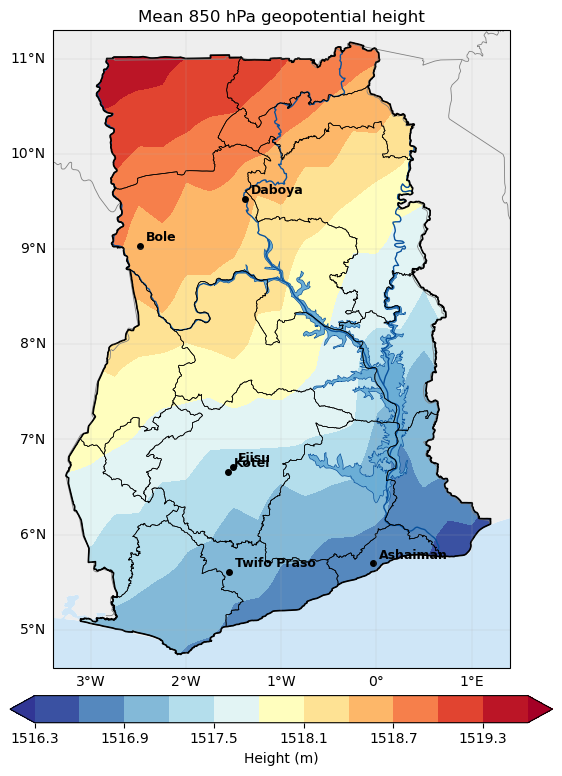

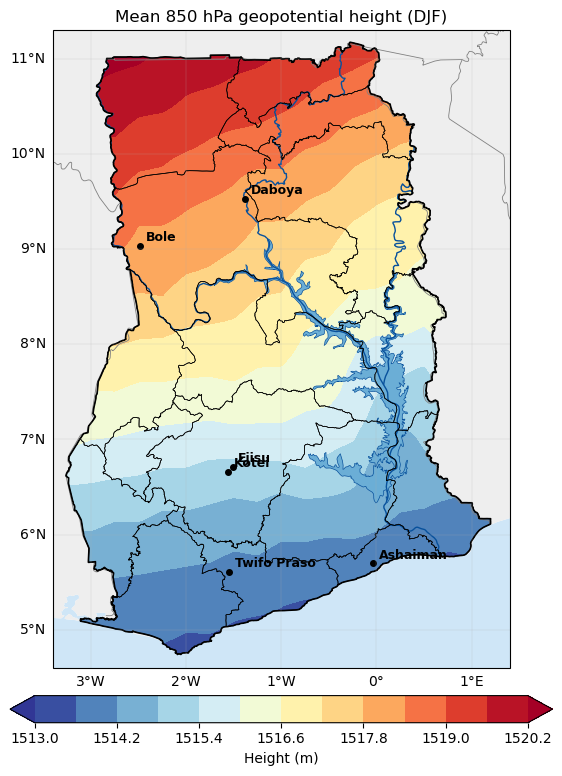

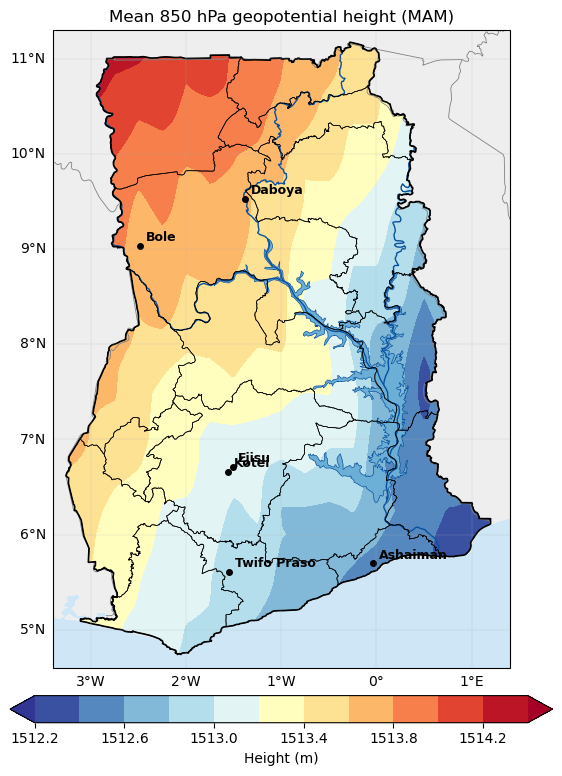

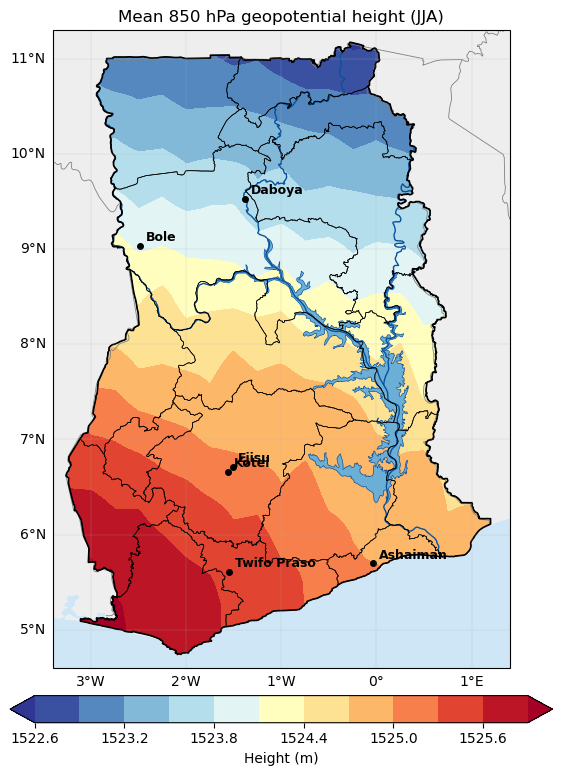

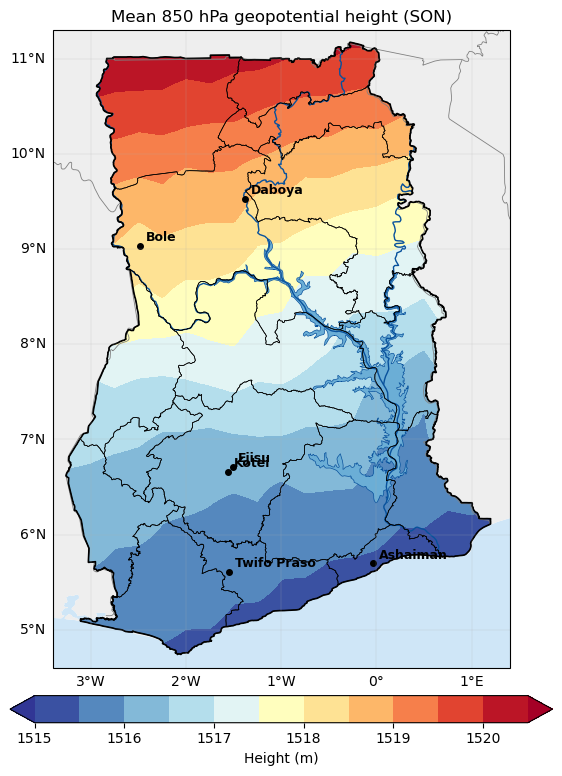

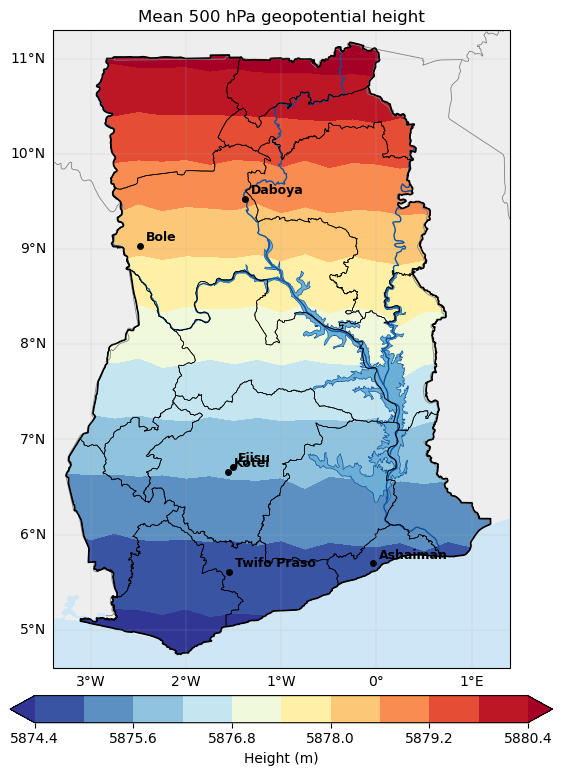

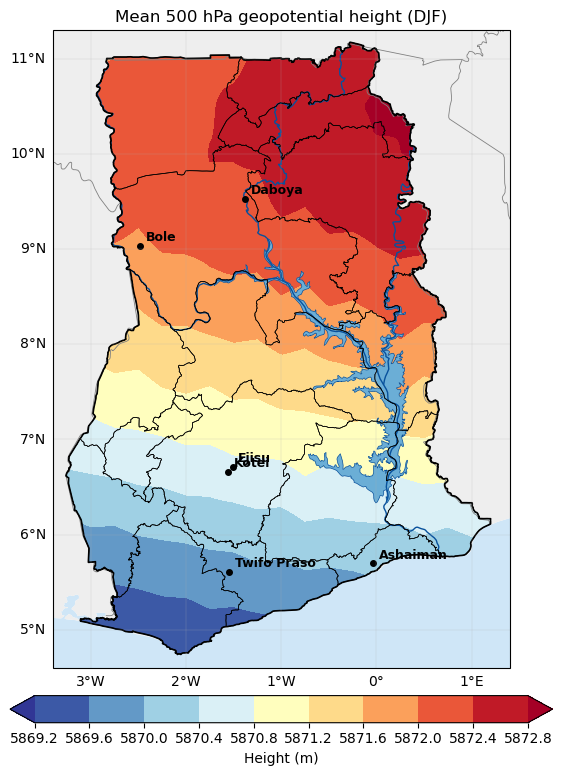

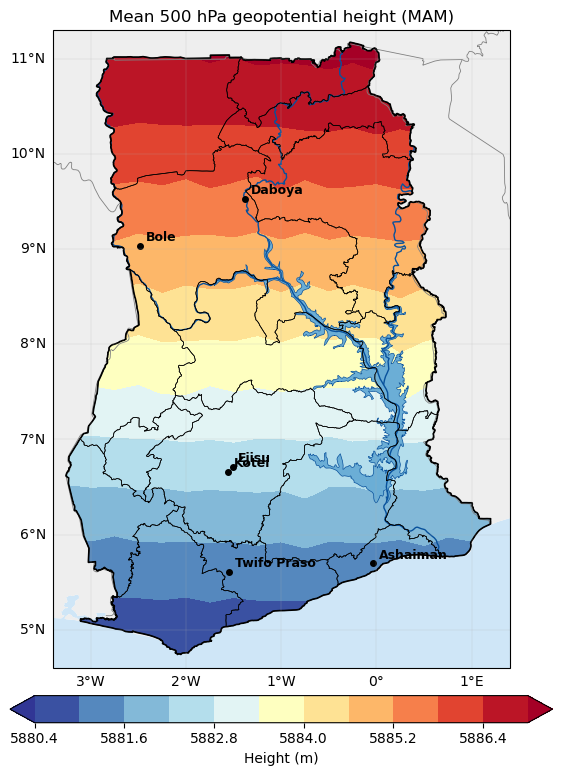

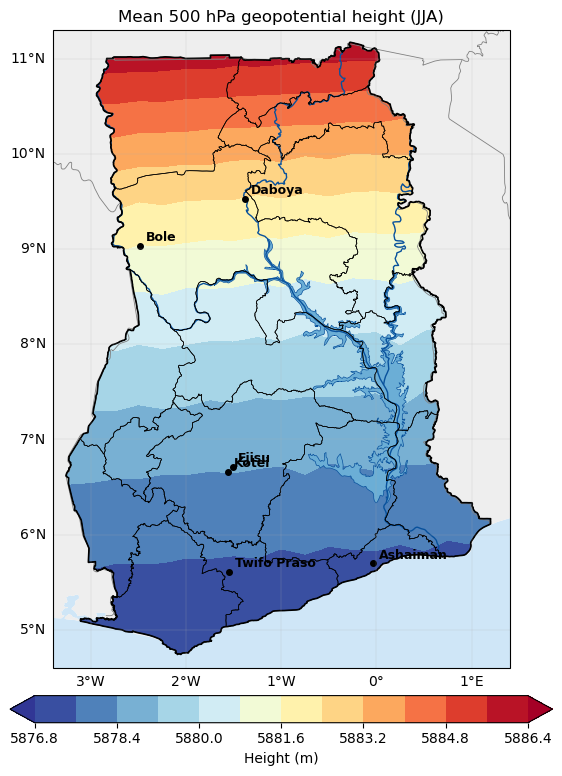

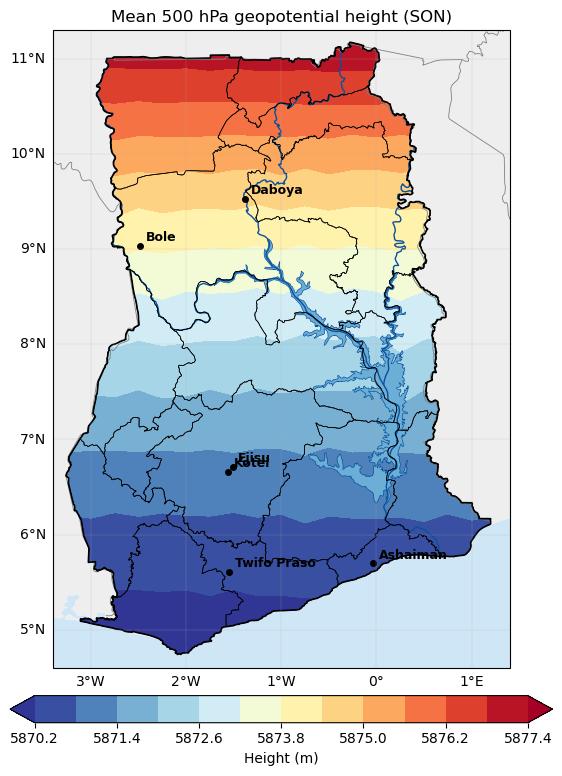

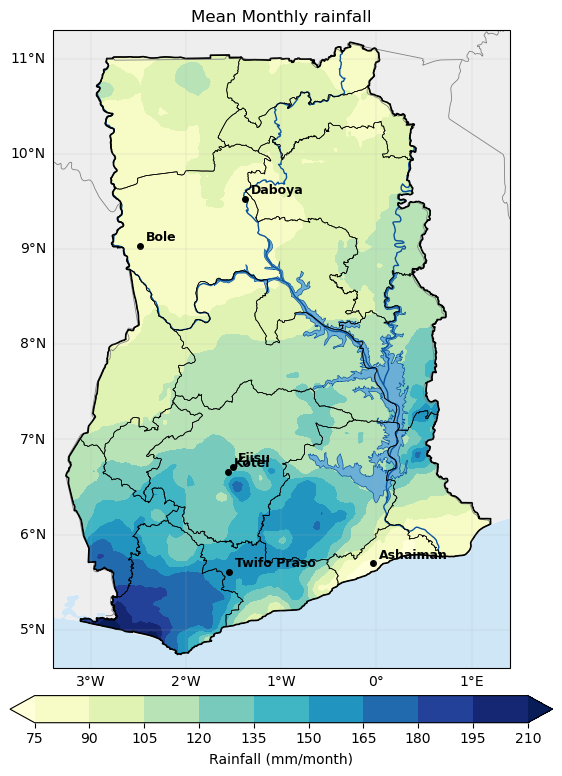

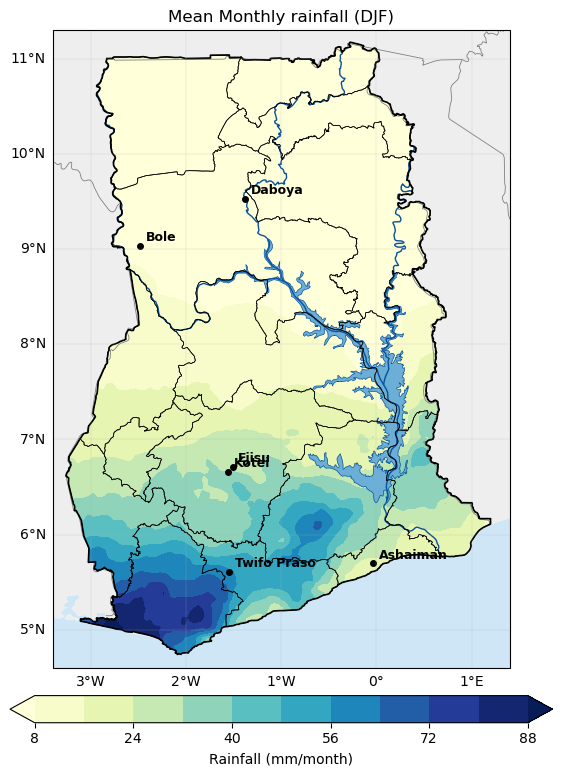

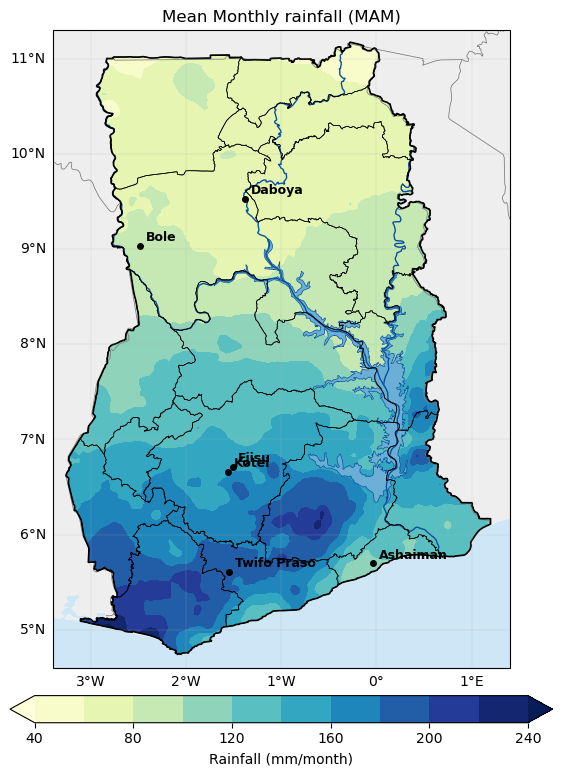

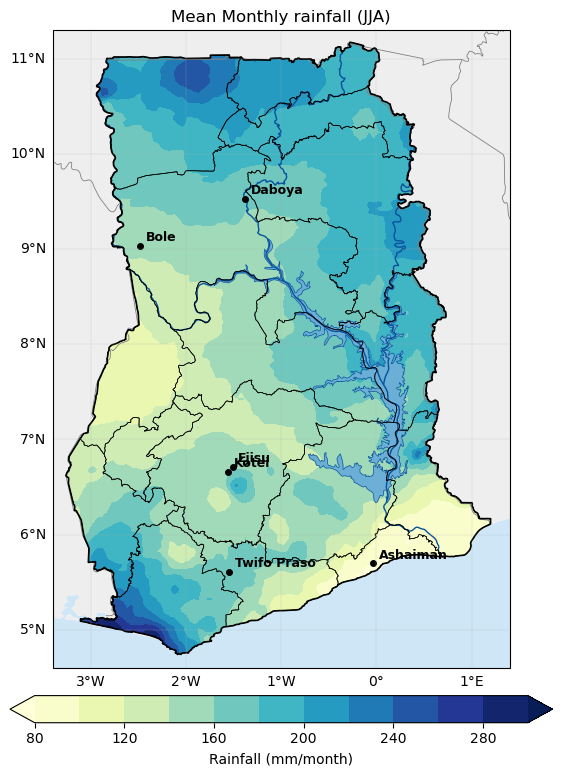

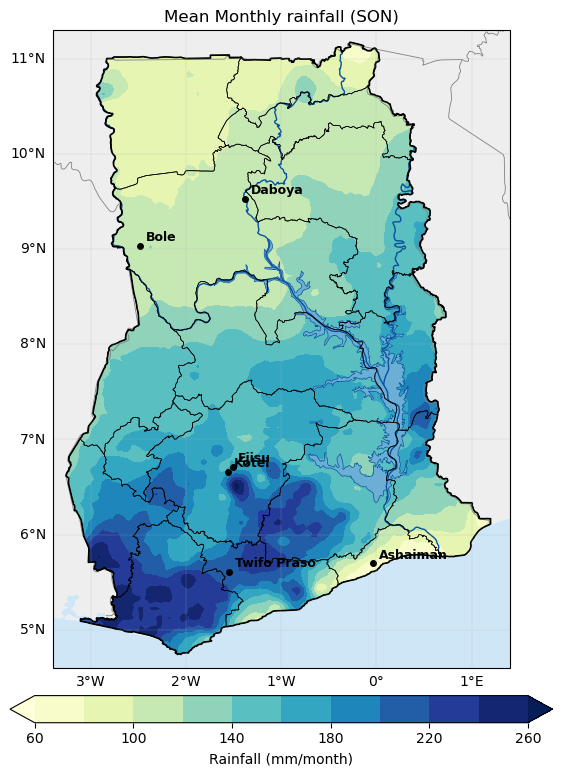

               z850    z500   rain
Ashaiman     1516.7  5874.9   68.0
Kotei        1517.4  5875.8  123.9
Ejisu        1517.4  5875.8  125.5
Daboya       1518.6  5878.7   85.5
Bole         1518.6  5878.1   89.3
Twifo Praso  1517.0  5874.6  156.3


In [10]:
import glob, numpy as np, pandas as pd, xarray as xr, geopandas as gpd
import matplotlib.pyplot as plt, cartopy.crs as ccrs, cartopy.feature as cf
import cartopy.io.shapereader as shp
from cartopy.mpl.path import shapely_to_path
from matplotlib.patches import PathPatch
from matplotlib.patches import PathPatch

# ---------------- settings ----------------
GH_PATH = r"C:\Users\jibbs\Downloads\gha_admin_boundaries.shp"
GH_LAYER, REGION_LAYER = "gha_admin0", "gha_admin1"
GH_FILE, GH500_FILE, RAIN_DIR = "GP(Z).nc", "GP(Z).nc", "chirps_rainfall"
BOX = dict(longitude=slice(-3.5, 1.5), latitude=slice(4.5, 11.5))

# (lon, lat) in decimal degrees, west is negative
places = {"Ashaiman":    (-0.0348, 5.6995),
          "Kotei":       (-1.5580, 6.6618),
          "Ejisu":       (-1.5112, 6.7150),
          "Daboya":      (-1.3837, 9.5303),
          "Bole":        (-2.4834, 9.0345),
          "Twifo Praso": (-1.5451, 5.6070)}

# ---------------- data ----------------
ren = {"lat": "latitude", "lon": "longitude", "valid_time": "time",
       "level": "pressure_level", "plev": "pressure_level"}
std = lambda d: d.rename({k: v for k, v in ren.items() if k in d.dims or k in d.coords})

files = sorted(glob.glob(f"{RAIN_DIR}/*.nc"))
print(len(files), "rainfall files")
rain = xr.concat([std(xr.open_dataset(f)).sortby("latitude").sel(**BOX).load() for f in files],
                 "time").sortby("time")["precip"]
rf = rain.resample(time="MS").sum(min_count=1)                       # mm/month

def height(file, lev):                                               # geopotential -> height (m)
    d = std(xr.open_dataset(file))
    return ((d["z"].sel(pressure_level=lev) / 9.80665)
            .sortby("latitude").sel(**BOX).resample(time="MS").mean())

fields = {"z850": (height(GH_FILE, 850), "850 hPa geopotential height", "Height (m)", "RdYlBu_r"),
          "z500": (height(GH500_FILE, 500), "500 hPa geopotential height", "Height (m)", "RdYlBu_r"),
          "rain": (rf, "Monthly rainfall", "Rainfall (mm/month)", "YlGnBu")}

# ---------------- shapes ----------------
ghana   = gpd.read_file(GH_PATH, layer=GH_LAYER).to_crs(4326).union_all()
regions = gpd.read_file(GH_PATH, layer=REGION_LAYER).to_crs(4326).geometry
rivers  = [g.intersection(ghana) for g in shp.Reader(shp.natural_earth("10m", "physical", "rivers_lake_centerlines")).geometries() if g.intersects(ghana)]
lakes   = [g.intersection(ghana) for g in shp.Reader(shp.natural_earth("10m", "physical", "lakes")).geometries() if g.intersects(ghana)]

# ---------------- map function ----------------
def mapit(f, title, unit, cmap, fname):
    f = f.sortby("latitude").sortby("longitude")
    f = f.interp(longitude=np.arange(float(f.longitude.min()), float(f.longitude.max()), .02),
                 latitude=np.arange(float(f.latitude.min()), float(f.latitude.max()), .02))
    pc = ccrs.PlateCarree()
    fig, ax = plt.subplots(figsize=(7, 9), subplot_kw=dict(projection=pc))
    ax.set_extent([-3.4, 1.4, 4.6, 11.3])
    ax.add_feature(cf.OCEAN, fc="#cfe6f7"); ax.add_feature(cf.LAND, fc="#eeeeee")
#cfe6f7"); ax.add_feature(cf.LAND, fc="
#eeeeee")
    ax.add_feature(cf.BORDERS, ec="gray", lw=.6)
    c = ax.contourf(f.longitude, f.latitude, f, levels=12, cmap=cmap, extend="both", transform=pc)
    clip = PathPatch(shapely_to_path(ghana), transform=pc, fc="none", ec="none")
    ax.add_patch(clip); c.set_clip_path(clip)
    ax.add_geometries(lakes, pc, fc="#6baed6", ec="#08519c", lw=.5)
#6baed6", ec="
#08519c", lw=.5)
    ax.add_geometries(rivers, pc, fc="none", ec="#08519c", lw=1)
#08519c", lw=1)
    ax.add_geometries(regions, pc, fc="none", ec="k", lw=.5)
    ax.add_geometries([ghana], pc, fc="none", ec="k", lw=1.2)
    for n, (x, y) in places.items():
        ax.plot(x, y, "ko", ms=4, transform=pc)
        ax.text(x + .06, y + .05, n, fontsize=9, fontweight="bold", transform=pc)
    ax.gridlines(draw_labels=dict(bottom=True, left=True), lw=.3, alpha=.5)
    plt.colorbar(c, orientation="horizontal", pad=.04, fraction=.04, label=unit)
    ax.set_title(title); fig.savefig(fname, dpi=300, bbox_inches="tight"); plt.show(); plt.close()

# ---------------- run: annual + 4 seasons ----------------
for key, (da, name, unit, cmap) in fields.items():
    seas = da.groupby("time.season").mean("time")
    mapit(da.mean("time"), f"Mean {name}", unit, cmap, f"{key}_annual.png")
    for s in ["DJF", "MAM", "JJA", "SON"]:
        mapit(seas.sel(season=s), f"Mean {name} ({s})", unit, cmap, f"{key}_{s}.png")

# ---------------- values at the six places ----------------
tab = pd.DataFrame({k: {n: float(da.sel(longitude=x, latitude=y, method="nearest").mean("time"))
                        for n, (x, y) in places.items()} for k, (da, *_) in fields.items()})
print(tab.round(1)); tab.to_csv("location_means.csv")

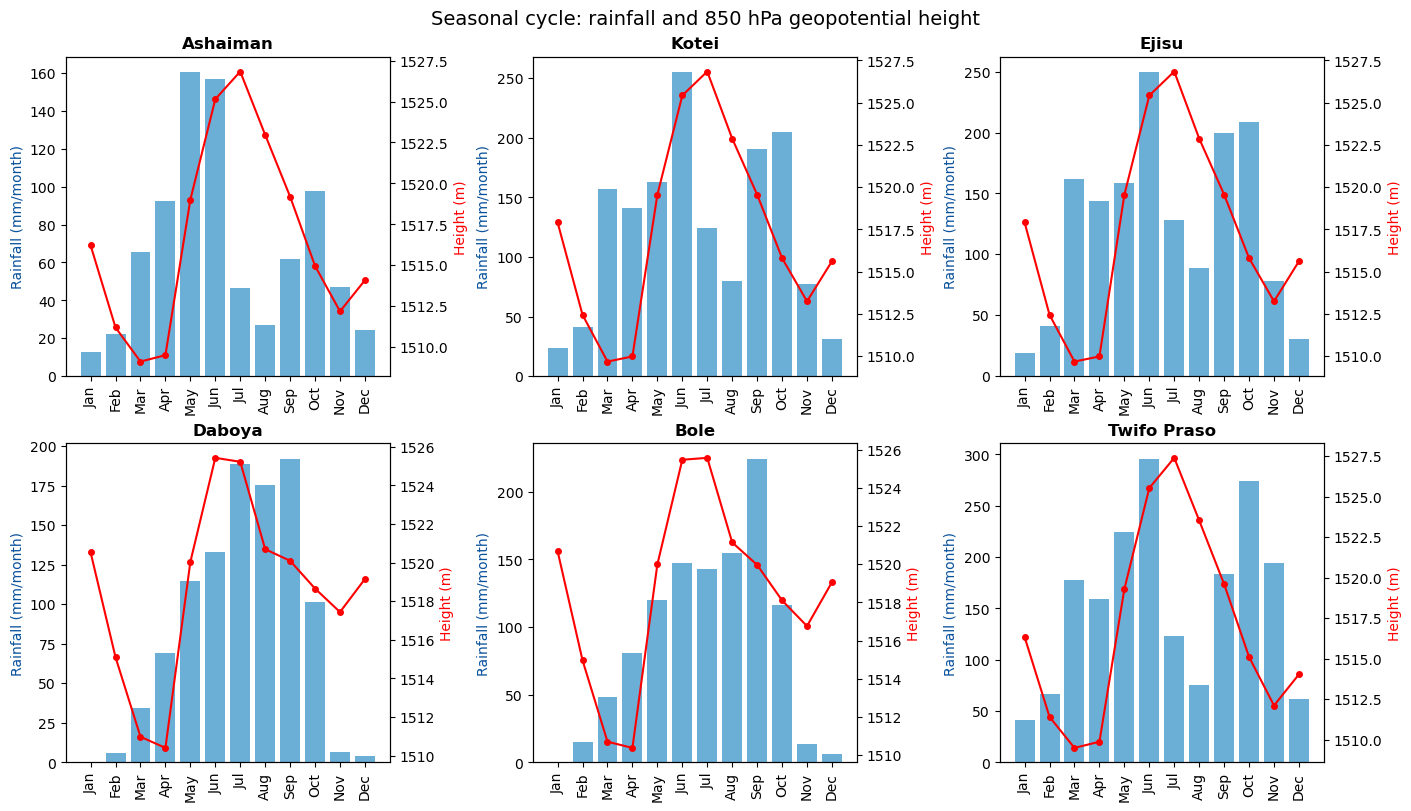

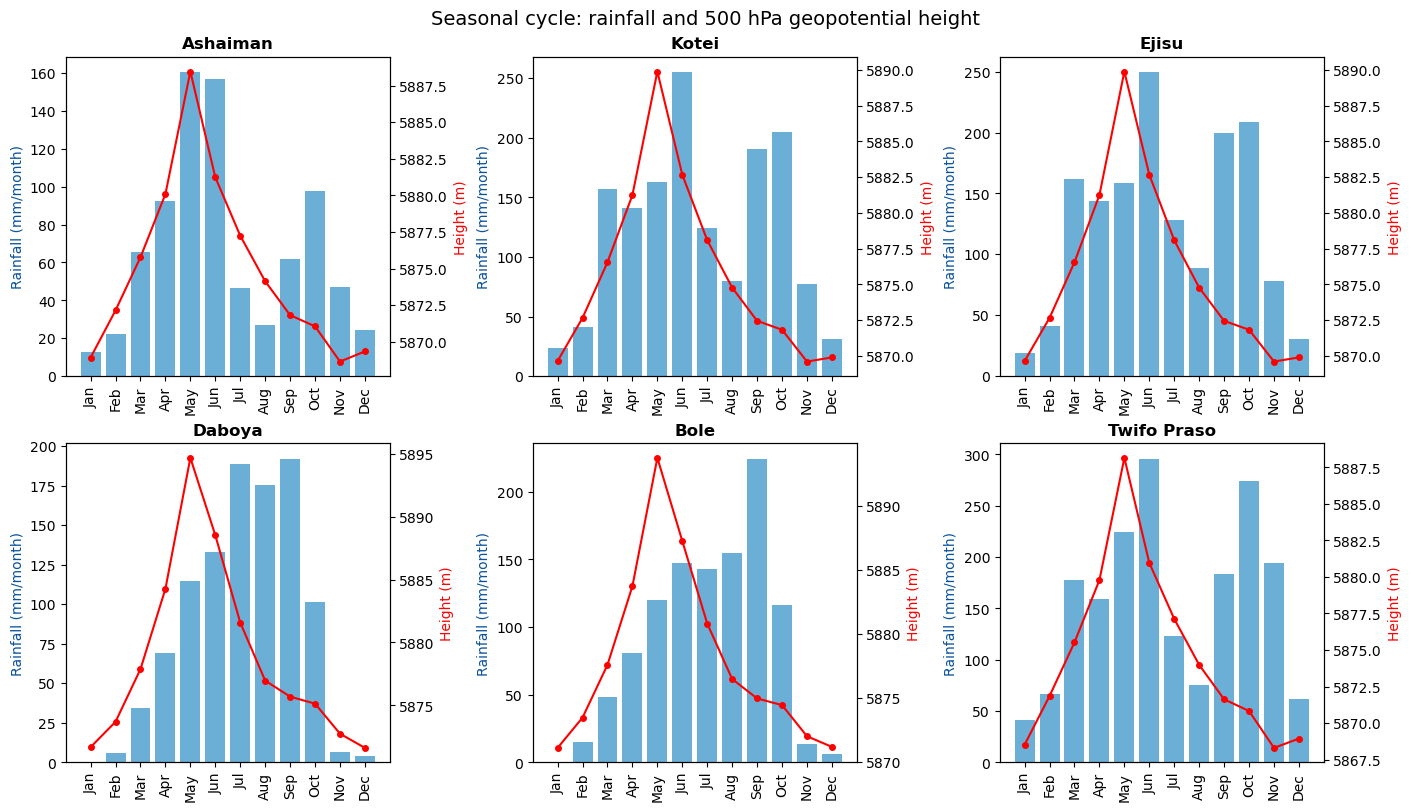

               z850                            z500                          \
season          DJF     MAM     JJA     SON     DJF     MAM     JJA     SON   
Ashaiman     1513.8  1512.5  1525.0  1515.4  5870.1  5881.4  5877.5  5870.5   
Kotei        1515.3  1513.1  1525.1  1516.2  5870.7  5882.6  5878.5  5871.3   
Ejisu        1515.3  1513.1  1525.1  1516.2  5870.7  5882.6  5878.5  5871.3   
Daboya       1518.3  1513.8  1523.8  1518.7  5872.3  5885.6  5882.4  5874.5   
Bole         1518.2  1513.7  1524.1  1518.3  5871.9  5885.0  5881.5  5873.8   
Twifo Praso  1513.9  1512.9  1525.5  1515.6  5869.8  5881.2  5877.4  5870.2   

             rain                       
season        DJF    MAM    JJA    SON  
Ashaiman     19.9  106.2   76.9   68.9  
Kotei        31.7  153.8  152.9  157.4  
Ejisu        30.1  154.5  155.4  162.0  
Daboya        3.5   72.7  165.7  100.0  
Bole          7.3   83.2  148.5  118.2  
Twifo Praso  56.3  186.9  164.8  217.3  


In [11]:
mon = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
point = lambda da, x, y: da.sel(longitude=x, latitude=y, method="nearest")
clim  = lambda da: da.groupby("time.month").mean("time")      # 12-month climatology

# ---- annual cycle: rainfall (bars) + geopotential height (line), one figure per level ----
for key in [k for k in fields if k != "rain"]:
    da, name, unit, _ = fields[key]
    fig, axs = plt.subplots(2, 3, figsize=(14, 8), sharex=False, constrained_layout=True)
    for ax, (n, (x, y)) in zip(axs.flat, places.items()):
        ax.bar(range(1, 13), clim(point(rf, x, y)), color="#6baed6")
        ax2 = ax.twinx()
        ax2.plot(range(1, 13), clim(point(da, x, y)), "r-o", ms=4)
        ax.set_title(n, fontweight="bold")
        ax.set_xticks(range(1, 13))
        ax.set_xticklabels(mon, rotation=90)
        ax.tick_params(axis="x", labelbottom=True)        # force month labels on every panel
        ax.set_ylabel("Rainfall (mm/month)", color="#08519c")
        ax2.set_ylabel(unit, color="r")
    fig.suptitle(f"Seasonal cycle: rainfall and {name}", fontsize=14)
    fig.savefig(f"seasonal_cycle_{key}.png", dpi=300)
    plt.show()
# ---- seasonal means table (DJF, MAM, JJA, SON) for every variable ----
order = ["DJF", "MAM", "JJA", "SON"]
season_table = pd.concat(
    {k: pd.DataFrame({n: point(da, x, y).groupby("time.season").mean("time").to_series()
                      for n, (x, y) in places.items()}).T[order]
     for k, (da, *_) in fields.items()}, axis=1)
print(season_table.round(1)); season_table.to_csv("seasonal_means_locations.csv")

kind           raw anomaly    raw anomaly
level         z850    z850   z500    z500
place                                    
Ashaiman      0.14   -0.07  0.42*    0.05
Kotei         0.15   -0.13  0.24*   -0.13
Ejisu         0.15   -0.11  0.22*   -0.13
Daboya       0.27*  -0.25*   0.2*  -0.19*
Bole         0.24*   -0.18  0.21*   -0.15
Twifo Praso    0.1   -0.08  0.21*   -0.06


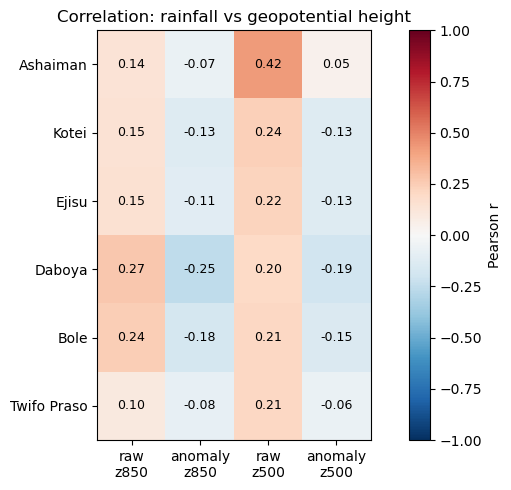

In [12]:
from scipy.stats import pearsonr

series = lambda da, x, y: point(da, x, y).to_series()
anom   = lambda s: s - s.groupby(s.index.month).transform("mean")   # remove the seasonal cycle
levels = [k for k in fields if k != "rain"]

rows = []
for n, (x, y) in places.items():
    for k in levels:
        d = pd.concat([series(rf, x, y), series(fields[k][0], x, y)], axis=1, keys=["r", "z"]).dropna()
        for kind, f in [("raw", lambda s: s), ("anomaly", anom)]:
            r, p = pearsonr(f(d.r), f(d.z))
            rows.append(dict(place=n, level=k, kind=kind, r=r, p=p, n=len(d)))
res = pd.DataFrame(rows)

# table of r values, * where p < 0.05
res["txt"] = res.r.round(2).astype(str) + np.where(res.p < .05, "*", "")
table = res.pivot(index="place", columns=["kind", "level"], values="txt").reindex(list(places))
print(table); table.to_csv("correlations.csv")

# heatmap of r
rr = res.pivot(index="place", columns=["kind", "level"], values="r").reindex(list(places))
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(rr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(rr.shape[1])); ax.set_xticklabels([f"{a}\n{b}" for a, b in rr.columns])
ax.set_yticks(range(rr.shape[0])); ax.set_yticklabels(rr.index)
for i in range(rr.shape[0]):
    for j in range(rr.shape[1]):
        ax.text(j, i, f"{rr.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, label="Pearson r"); ax.set_title("Correlation: rainfall vs geopotential height")
fig.tight_layout(); fig.savefig("correlations.png", dpi=300); plt.show()

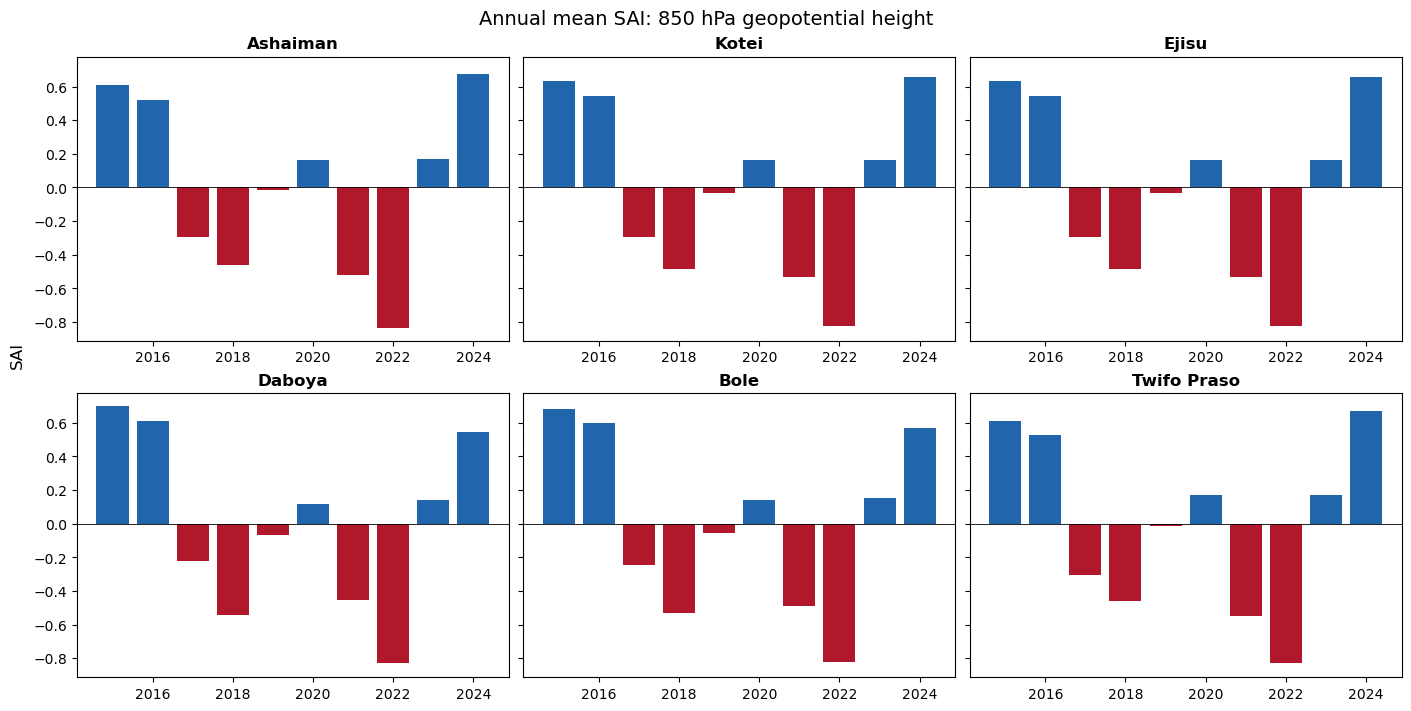

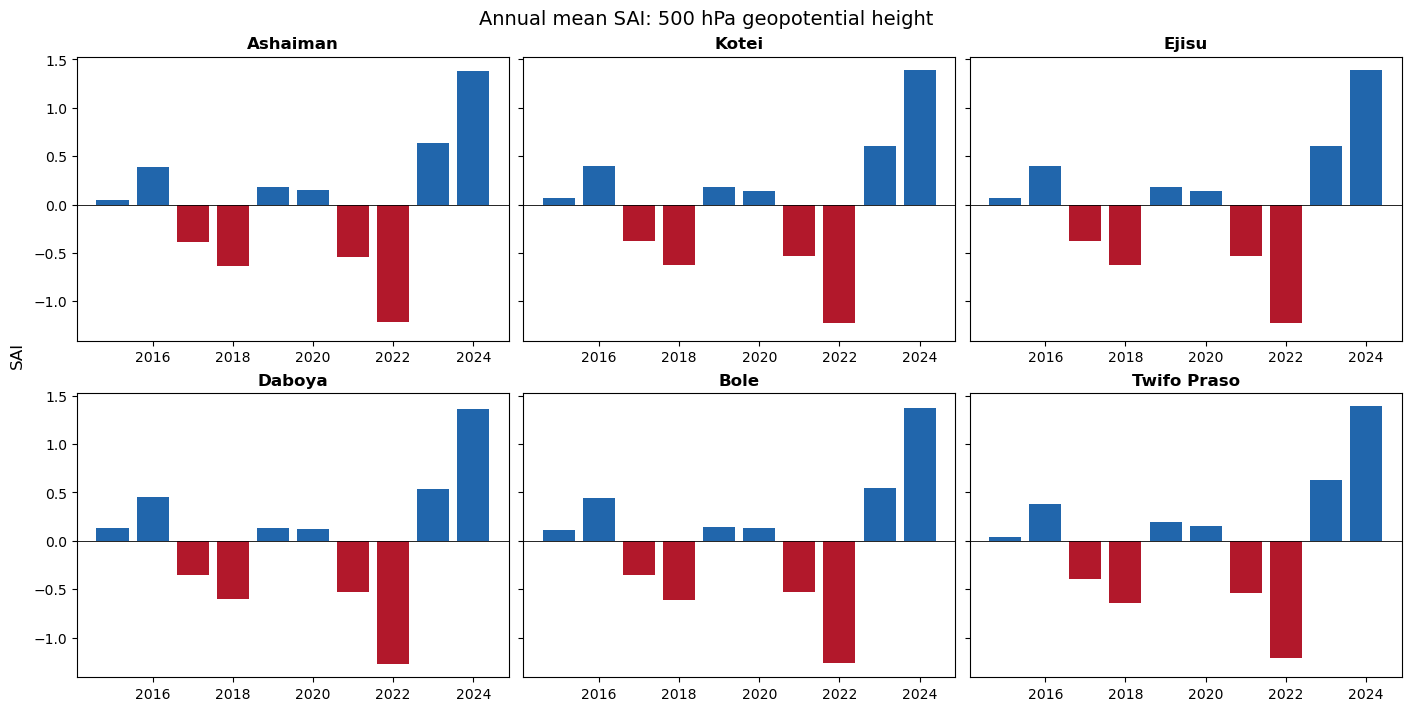

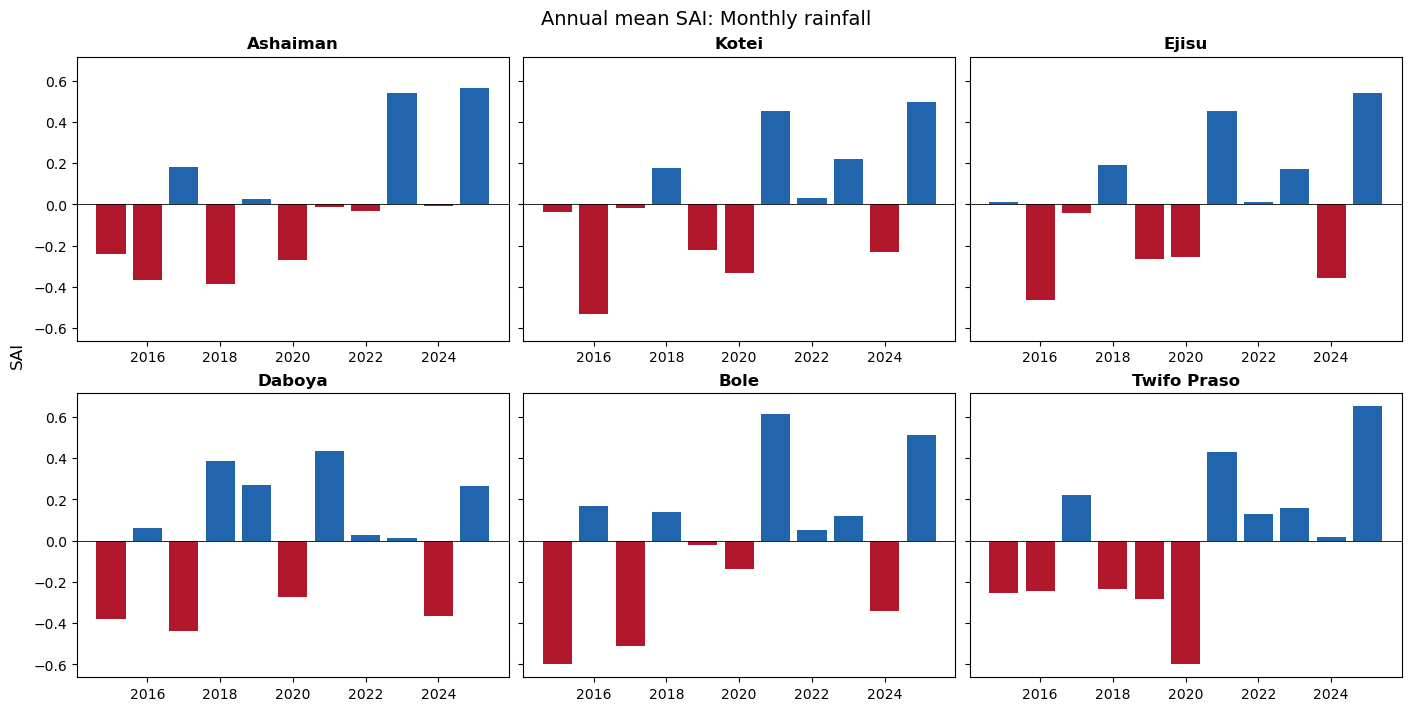

In [13]:
sai = lambda s: (s - s.groupby(s.index.month).transform("mean")) / s.groupby(s.index.month).transform("std")

sai_m = {}
for k, (da, name, unit, _) in fields.items():
    sai_m[k] = pd.DataFrame({n: sai(point(da, x, y).to_series()) for n, (x, y) in places.items()})
    ann = sai_m[k].groupby(sai_m[k].index.year).mean()          # annual mean SAI
    fig, axs = plt.subplots(2, 3, figsize=(14, 7), sharey=True, constrained_layout=True)
    for ax, n in zip(axs.flat, places):
        ax.bar(ann.index, ann[n], color=np.where(ann[n] >= 0, "#2166ac", "#b2182b"))
        ax.axhline(0, color="k", lw=.6)
        ax.set_title(n, fontweight="bold")
    fig.suptitle(f"Annual mean SAI: {name}", fontsize=14)
    fig.supylabel("SAI")
    fig.savefig(f"SAI_{k}.png", dpi=300); plt.show()
    sai_m[k].to_csv(f"SAI_monthly_{k}.csv")

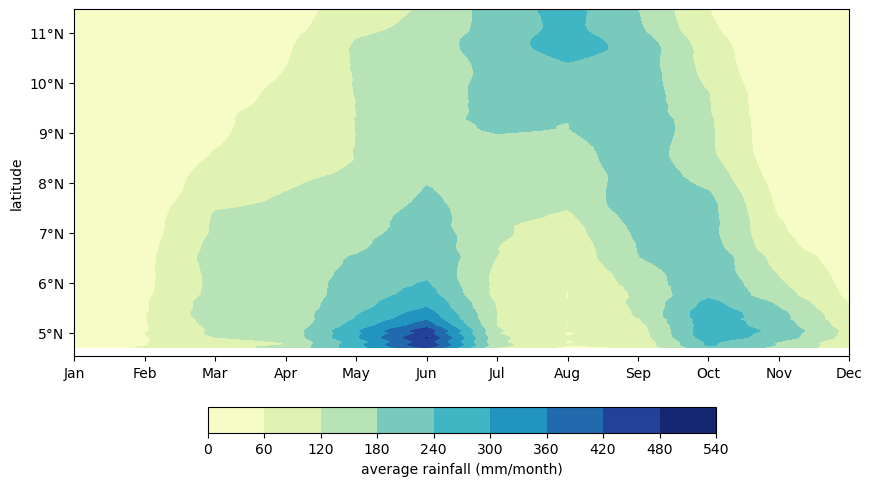

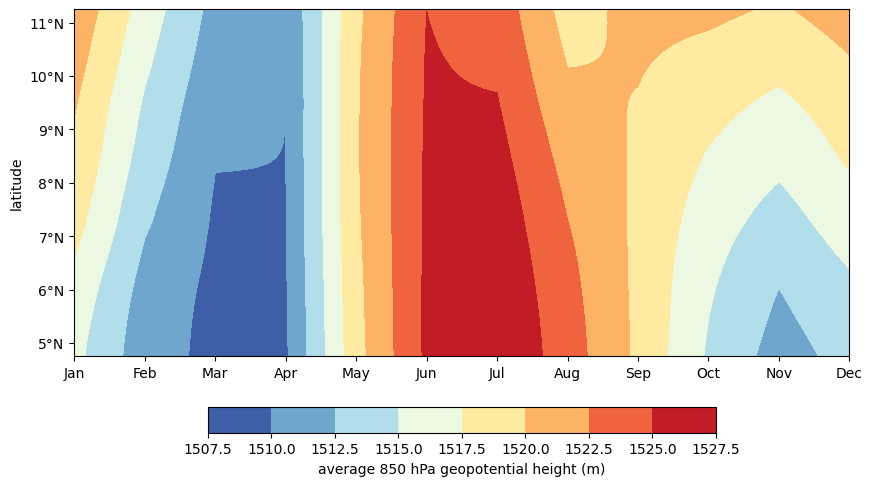

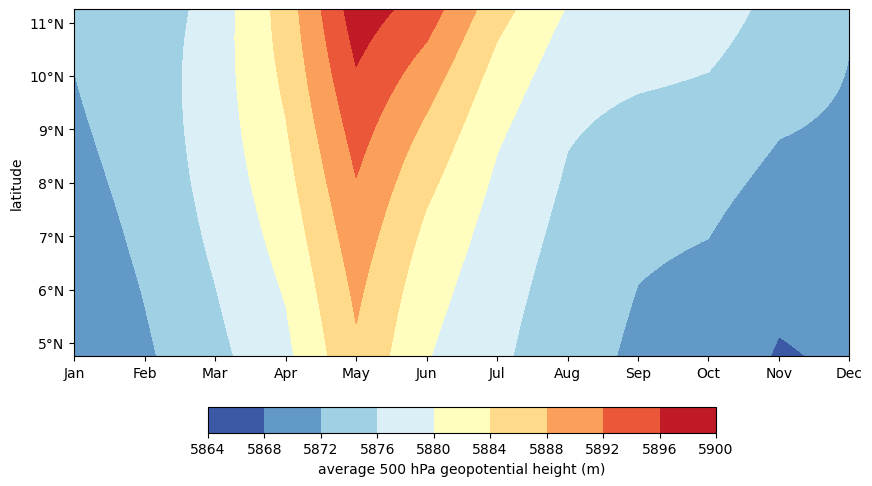

In [14]:
import numpy as np, matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# ---------------- options ----------------
RAIN_PER_DAY = False    # True -> rainfall in mm/day (like your example), False -> mm/month
SHOW_PLACES  = False    # True -> dashed lines at the latitudes of the six places

mon = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
labels = {"rain": "average rainfall (mm/day)" if RAIN_PER_DAY else "average rainfall (mm/month)",
          "z850": "average 850 hPa geopotential height (m)",
          "z500": "average 500 hPa geopotential height (m)"}
lat_fmt = FuncFormatter(lambda v, _: f"{abs(v):.0f}°{'N' if v >= 0 else 'S'}")

# ---------------- Hovmöller: latitude vs month ----------------
for k in ["rain", "z850", "z500"]:
    da, name, unit, cmap = fields[k]
    if k == "rain" and RAIN_PER_DAY:
        da = da / da.time.dt.days_in_month                     # mm/month -> mm/day

    h = da.mean("longitude").sortby("latitude").groupby("time.month").mean("time")    # (month, latitude)
    h = h.interp(month=np.linspace(1, 12, 111),
                 latitude=np.linspace(float(h.latitude.min()), float(h.latitude.max()), 150))   # smooth shading

    fig, ax = plt.subplots(figsize=(10, 5.5))
    c = ax.contourf(h.month, h.latitude, h.T, levels=8, cmap=cmap)
    ax.set_xticks(range(1, 13)); ax.set_xticklabels(mon)
    ax.yaxis.set_major_formatter(lat_fmt)
    ax.set_ylabel("latitude")

    if SHOW_PLACES:
        for n, (x, y) in places.items():
            ax.axhline(y, ls="--", lw=.6, color="k")
            ax.text(12.05, y, n, fontsize=7, va="center")

    cb = fig.colorbar(c, ax=ax, orientation="horizontal", pad=.12, fraction=.06)
    cb.set_label(labels[k])
    fig.savefig(f"hovmoller_{k}.png", dpi=300, bbox_inches="tight")
    plt.show()
    

In [15]:
import os, glob, shutil

os.makedirs("ppt_figures", exist_ok=True)               # creates the folder if it doesn't exist

for f in glob.glob("*.png"):                            # every PNG in the working folder
    shutil.copy(f, "ppt_figures")                       # copy (the originals stay where they are)

for f in glob.glob("*.csv"):                            # optional: the tables too
    shutil.copy(f, "ppt_figures")

print(sorted(os.listdir("ppt_figures")))
print("Folder location:", os.path.abspath("ppt_figures"))

["Bro's wedding invitation 2.png", "Bro's wedding invitation.png", 'Car_sales.csv', 'ERA5_GHA_2m_Max_1981_2025.nc.csv', 'Ghana_Zone_Temperature_Statistics.csv', 'INVITE.png', 'SAI_monthly_rain.csv', 'SAI_monthly_z500.csv', 'SAI_monthly_z850.csv', 'SAI_rain.png', 'SAI_z500.png', 'SAI_z850.png', 'TAMSAT_data.csv', 'WEDDING INVITATION.png', 'accra_climatology.png', 'bolgatanga_climatology.png', 'climatology_1991_2020.csv', 'correlations.csv', 'correlations.png', 'era5_annual_average.csv', 'era5_monthly_average.csv', 'era5_statistics.csv', 'hovmoller_climatology.png', 'hovmoller_rain.png', 'hovmoller_timeseries.png', 'hovmoller_z500.png', 'hovmoller_z850.png', 'location_means.csv', 'map_annual_climatology.png', 'map_monthly_climatology.png', 'monthly_rainfall_maps.png', 'oni_correlations.csv', 'oni_table.csv', 'rain_DJF.png', 'rain_JJA.png', 'rain_MAM.png', 'rain_SON.png', 'rain_annual.png', 'seasonal_cycle_z500.png', 'seasonal_cycle_z850.png', 'seasonal_means_locations.csv', 'wa_climatolo